In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

eps = 0.000001

save_tag = '7jul'

In [2]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rng(x):
    return x.max() - x.min()

def statistics(x):
    mean = np.mean(x)
    sd = np.std(x)
    median = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1
    return mean.item(), median.item(), sd.item(), iqr.item()


def remove_outlayer(x, method='3sigma', return_bin=True):
    mean, median, sd, iqr = statistics(x)
    if method == '3sigma':
        thr = 3               # 3 sigma
        z = (x - mean) / (sd + eps)
        binary = (z >= -thr) & (z <= thr)
        return binary if return_bin else x[binary]
    elif method == 'iqr':
        q1, q3 = np.percentile(x, [25, 75])
        binary = (x >= (q1 - 1.5*iqr)) &  (x <= (q3 + 1.5*iqr))
        return binary if return_bin else x[binary]
    else:
        print('Method not implemented')
        return None


def remove_outlayer_df(df, assay, method):
    """
    method = ('3sigma', 'iqr')
    """
    
    binary = []
    for i in df['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        binary.extend(remove_outlayer(x, method).tolist())
    binary = np.array(binary)
    df_new = df.loc[binary].copy()
    return df_new
    

def normalize(x, control, method='mean', scale=False):
    mean, median, sd, iqr = statistics(control)
    if not scale:
        sd, iqr = 1, 1
    if method == 'mean':
        return (x - mean) / sd if sd > eps else 0
    elif method == 'median':
        return (x - median) / (iqr) if iqr > eps else 0
    else:
        print('Method not implemented')
        return None


def normalize_df(df, df_ref, assay, method):
    df_ref[f'norm_{assay}'] = None
    for i in df_ref['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assay]
        control = df_ref.loc[df_ref['Plate_ID'] == i, assay]
        
        x = normalize(x, control, method=method, scale=True)
        df.loc[df['Plate_ID'] == i, f'norm_{assay}'] = x
        
        x = normalize(control, control, method=method, scale=True)
        df_ref.loc[df_ref['Plate_ID'] == i, f'norm_{assay}'] = x

    return df, df_ref
    

def emperical_p_value(x, null, alternative='two_sided', take_abs=False):
    if take_abs:
        null = np.abs(null)
        x = np.abs(x)
    if alternative == 'greater':
        p = np.mean(x <= null)
    elif alternative == 'less':
        p = np.mean(x >= null)
    elif  alternative == 'two_sided':
        p = np.mean(x <= null | x >= null)
    else:
        print('Invalid "alternative" parameter')
    return p


def boxplot_per_plate(df, assay, protein, title='', ordered=True, save_dir=None, ylim=None):
    # Plate-id orderes: 
    # to see original order use Plate_ID
    # to see them ordered based on numbers use Plate_ID_cat
    plate_id = 'Plate_ID_cat' if ordered else 'Plate_ID'
    
    plt.figure(figsize=(20, 6))

    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df[plate_id].unique())
    plt.vlines(np.arange(0, n_plate, 2), ymin = -100, ymax = 100, colors='gray', linestyles='dashed', linewidth=0.5)
    sns.boxplot(data=df, x=plate_id, y=assay)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def dotplot_per_plate(df, assay, protein, ids, title='', ordered=True, save_dir=None, ylim=None):
    
    plt.figure(figsize=(20, 6))
    df = df.loc[df['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df['Plate_ID_cat'].unique())
    
    df = df.loc[df['ID'].isin(ids)]
    
    plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
    plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)
    
    sns.stripplot(data=df, x='Plate_ID_cat', y=assay, hue='ID', dodge=True, jitter=True, size=4)
    
    plt.title(f'{assay} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assay.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()


def pos_ctrl_qc(df, protein, pos_ctrl, assay):
    df_tmp = df.loc[(df['Protein'] == protein) & (df['ID'] == pos_ctrl)].copy()
    x = remove_outlayer(np.array(df_tmp[assay]), method='iqr', return_bin=False)
    df_tmp[f'abnormal_{pos_ctrl}_{protein}_{assay}'] = 0
    df_tmp.loc[df_tmp[assay] > x.max(), f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_tmp.loc[df_tmp[assay] < x.min(), f'abnormal_{pos_ctrl}_{assay}'] = 1
    df_qc_updated = df_tmp.groupby('Plate_ID')[f'abnormal_{pos_ctrl}_{assay}'].sum()
    return df_qc_updated

In [3]:
# Read data
df_main = pd.read_excel("data/PO-ini2810_PAHcomplete_20250502.xlsx")
df_main = df_main.drop('Unnamed: 0', axis=1)
df_main.shape, len(df_main['Plate_ID'].unique())

((182688, 37), 519)

In [4]:
df_main.head()

,ID,Cxsmiles,Formula,MW,Purity,PO,Salt smiles,Salt_name,Salt_ratio,MW_salt,...,delta_SpSh_mean,SpSh_Warning,DMSO_SpSh_median,DMSO_SpSh_mean,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37
0,BH4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.253984,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN
1,BH4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.273610,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN
2,CSCS00104537142,CC(C(=O)N1CCC(C1)(C(=O)O)C(F)(F)F)N2C=NC=N2,C11H13F3N4O3,306.2411,100.0,ini2810,NaN,NaN,NaN,0.0,...,0.053081,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN
3,CSCS00133135693,CC1=NOC(=N1)C2CCN(CC2)C(=O)NC3=CC=C(F)C(F)=C3F,C15H15F3N4O2,340.3004,92.5,ini2810,NaN,NaN,NaN,0.0,...,0.041086,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN
4,CSCS00093835758,CN(CC(=O)NC1CCS(=O)(=O)C1)C=2N=CN=C3C=CSC23,C13H16N4O3S2,340.4211,100.0,ini2810,NaN,NaN,NaN,0.0,...,0.037858,NaN,2.903465,2.910569,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Find the control compounds
# Their 'Formula' should be 'NaN'
ctlr_compounds = df_main.loc[df_main['Formula'].isna(), 'ID'].unique()
ctlr_compounds

array(['BH4', 'UCR243', 'UCR102', 'DMSO'], dtype=object)

In [6]:
# Find the proteins
df_main['Protein'].unique()

array(['PAH-WT', 'failed', 'PAH-I65T'], dtype=object)

In [7]:
df_main[(df_main['Protein'] == 'PAH-WT') & (~df_main['ID'].isin(ctlr_compounds))].shape

(80000, 37)

In [8]:
df = df_main.dropna(subset = 'Thermal_Shift').copy()
df = df.dropna(subset = 'Spectral_Shift').copy()
df = df.loc[df['Protein'] != 'failed'].copy()
df['Protein'].unique()

array(['PAH-WT', 'PAH-I65T'], dtype=object)

In [9]:
df[(df['Protein'] == 'PAH-WT') & (~df['ID'].isin(ctlr_compounds))].shape

(79800, 37)

In [10]:
# Make categorical plate ids with sorted levels based on numbers
df_plate_ids = pd.DataFrame({'ids' : df['Plate_ID'].unique()})
df_plate_ids['ids_no_letter'] = [i[1:] if i[0].isalpha() else i for i in df_plate_ids['ids']]
df_plate_ids = df_plate_ids.sort_values('ids_no_letter')
df_plate = df_plate_ids['ids']
df['Plate_ID_cat'] = pd.Categorical(df['Plate_ID'], categories=df_plate, ordered=True)

In [11]:
# define df control (DMSO) and other
ctrl_id = 'DMSO'
df_ctrl = df.loc[df['ID'] == ctrl_id].copy()
df_other = df.loc[df['ID'] != ctrl_id].copy()

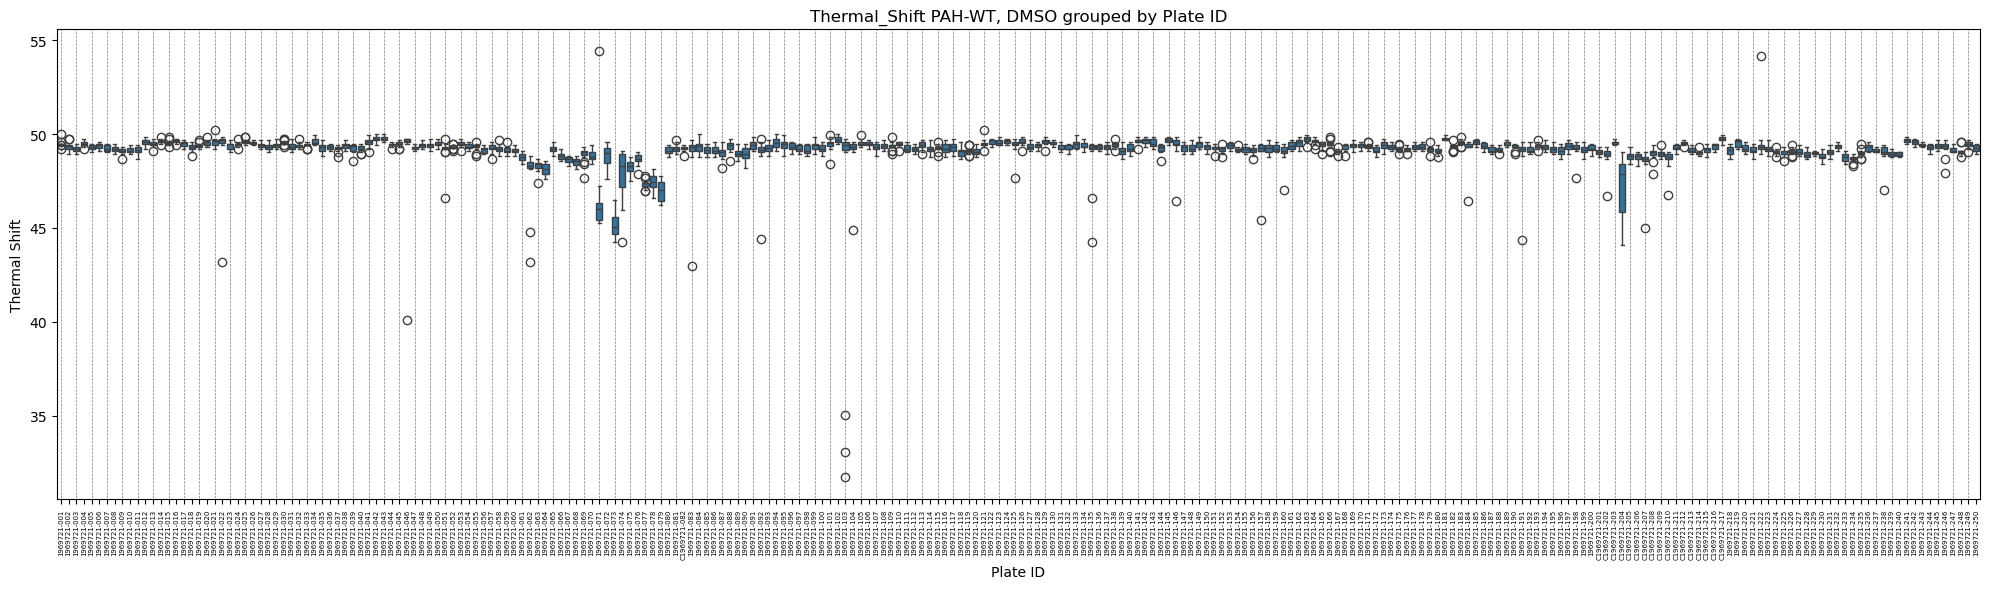

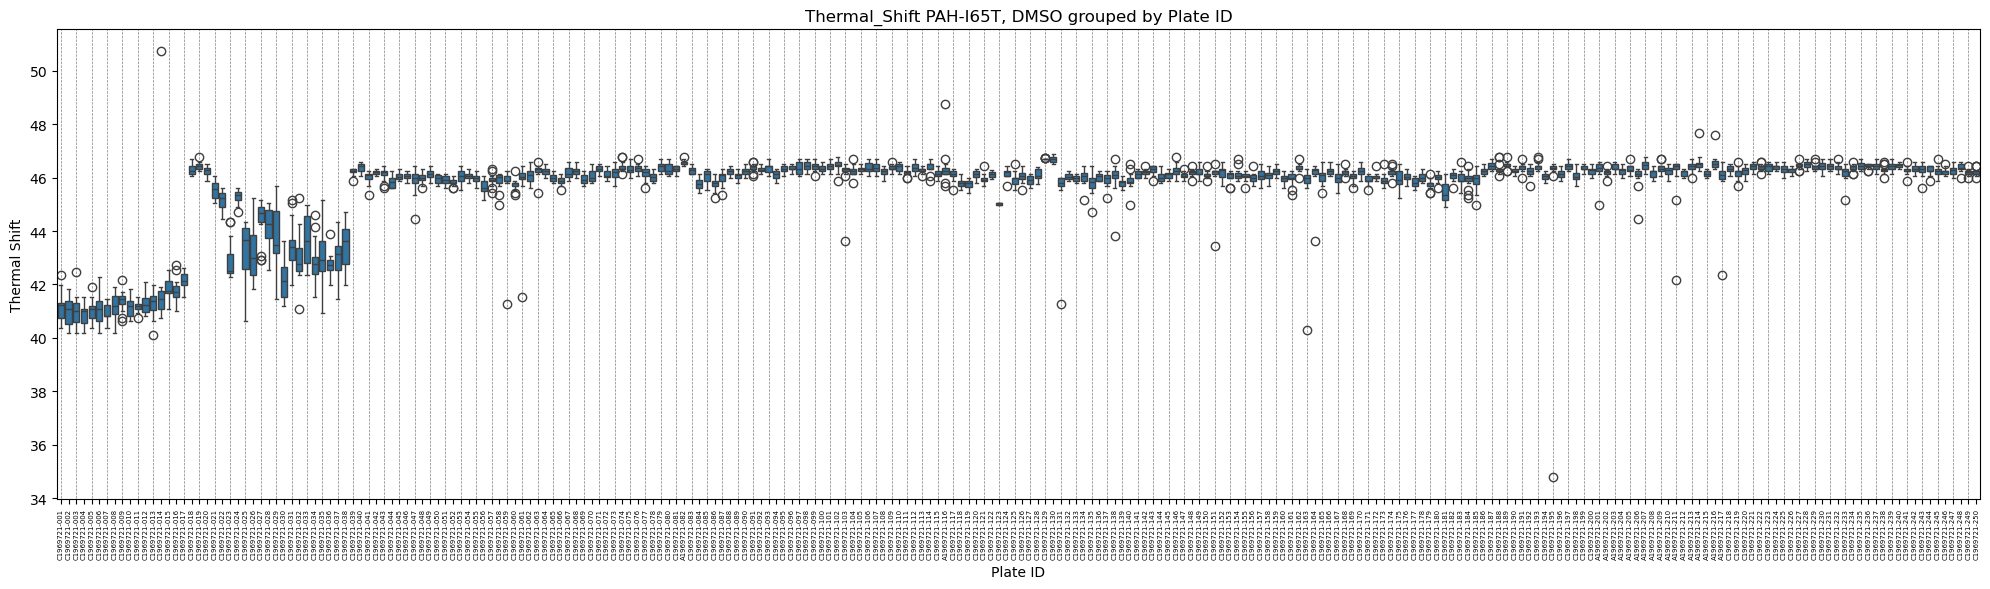

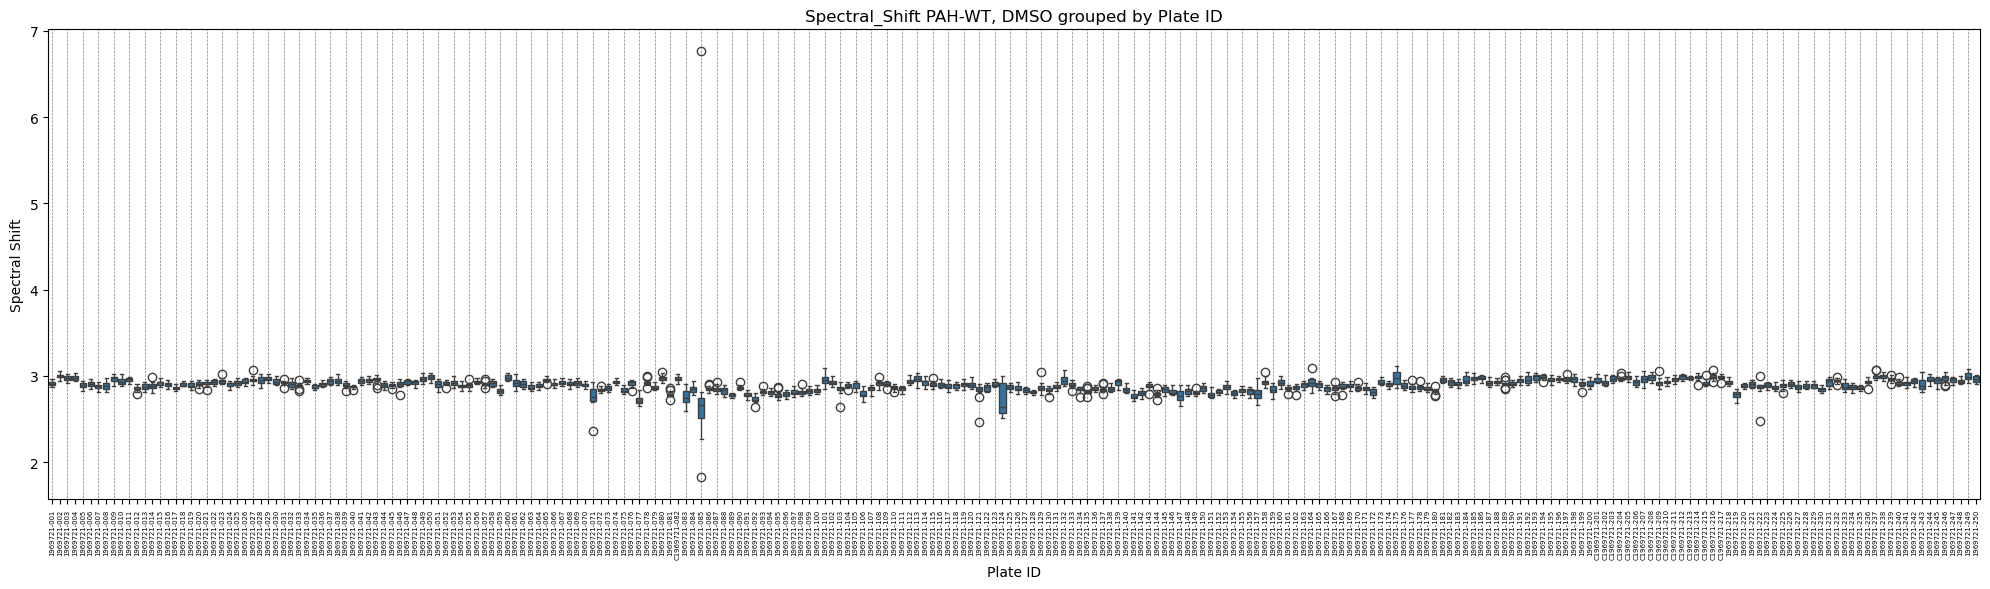

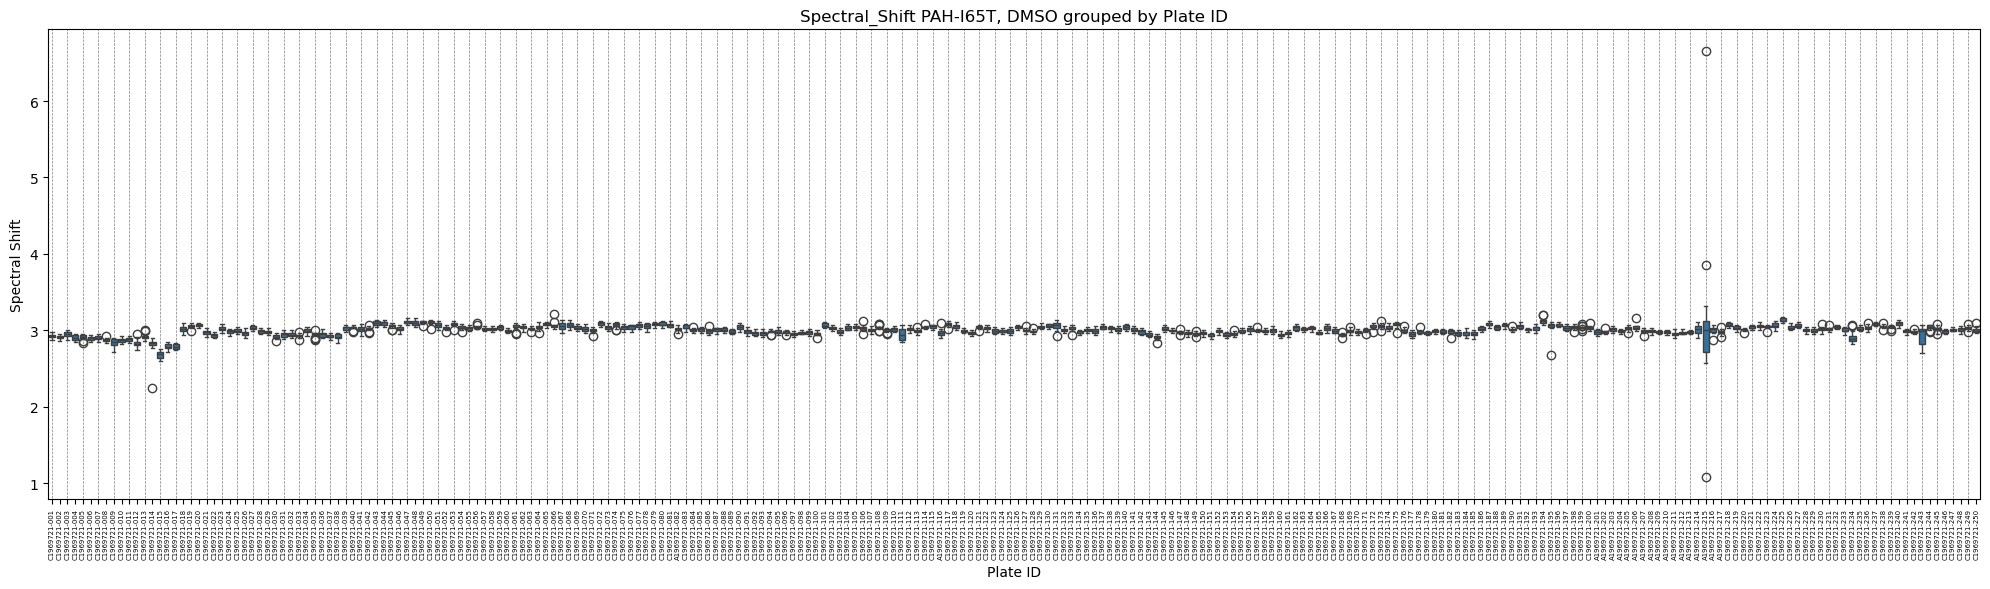

In [12]:
# Plot before outlier removal

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [13]:
# Get QC initial table
df_qc = (
    df_ctrl
    .groupby('Plate_ID_cat', observed=True)
    .agg({
        'Protein': 'first',
        'Thermal_Shift': ['median', iqr],
        'Spectral_Shift': ['median', iqr]
    })
)
df_qc.columns = ['Protein', 'TSA_median', 'TSA_iqr', 'SpSh_median', 'SpSh_iqr']
df_qc.head()

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr
Plate_ID_cat,,,,,
1969721-001,PAH-WT,49.4840,0.000000,2.903465,0.031402
C1969721-001,PAH-I65T,41.2325,0.563625,2.919414,0.030101
C1969721-002,PAH-I65T,41.0972,0.856700,2.916621,0.033232
1969721-002,PAH-WT,49.3487,0.180400,3.001054,0.034008
1969721-003,PAH-WT,49.2134,0.180400,2.976828,0.049121


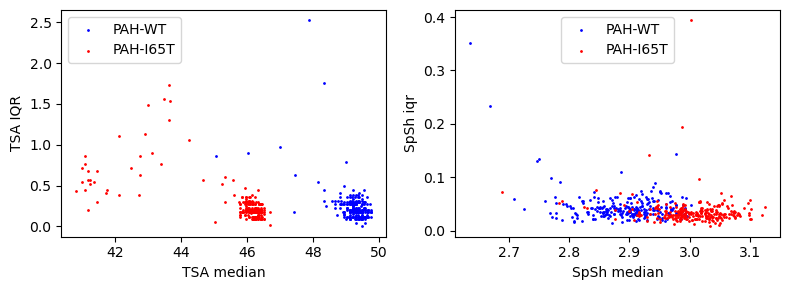

In [14]:
# Look at each plate

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# First subplot (TSA)
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_iqr'],
              s=1, color='blue', label='PAH-WT')
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_iqr'],
              s=1, color='red', label='PAH-I65T')
ax[0].set_xlabel('TSA median')
ax[0].set_ylabel('TSA IQR')
ax[0].legend()

# Second subplot (SpSh)
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_iqr'],
              s=1, color='blue', label='PAH-WT')
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_iqr'],
              s=1, color='red', label='PAH-I65T')
ax[1].set_xlabel('SpSh median')
ax[1].set_ylabel('SpSh iqr')
ax[1].legend()

plt.tight_layout()
plt.show()


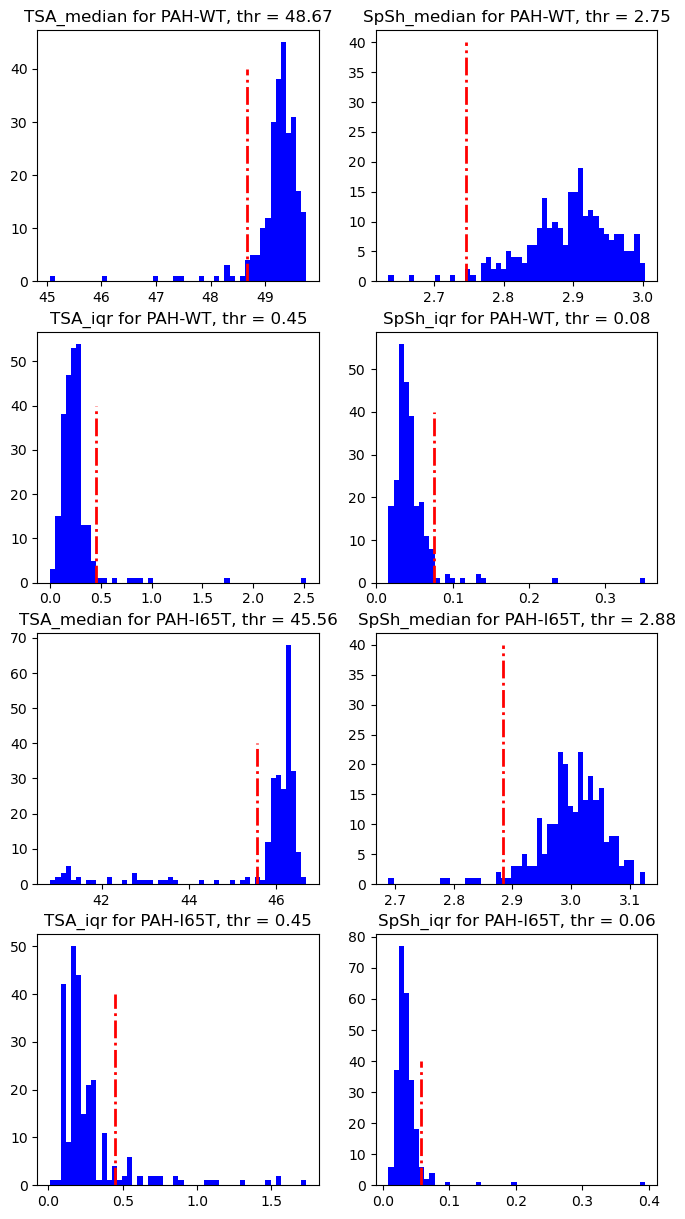

In [15]:
# Remove plates based on mean and IQR method
plot_outlier = []

fig, ax = plt.subplots(4, 2, figsize=(8, 15))
ax = ax.flatten()

i = 0
for prot in ['PAH-WT', 'PAH-I65T']:
    for col in ['TSA_median', 'SpSh_median', 'TSA_iqr', 'SpSh_iqr']:
        df_tmp = df_qc.loc[df_qc['Protein'] == prot].copy()
        x = remove_outlayer(np.array(df_tmp[col]), method='iqr', return_bin=False)

        if col.split('_')[1] in ['median', 'mean']:
            thr = x.min()
            plot_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))
        else:
            thr = x.max()
            plot_outlier.extend(list(df_tmp.loc[df_tmp[col] > thr].index))
            # thr = x.min()
            # plot_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))
        
        ax[i].hist(df_tmp[col], 50, color='blue');
        ax[i].vlines(thr, ymin=0, ymax=40, colors='red', linestyles='-.', linewidth=2)
        ax[i].set_title(f'{col} for {prot}, thr = {thr:.2f}');
        i += 1

In [16]:
df_qc['out_of_distribution'] = 'no'
df_qc.loc[df_qc.index.isin(plot_outlier), 'out_of_distribution'] = 'yes'
df_qc

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,out_of_distribution
Plate_ID_cat,,,,,,
1969721-001,PAH-WT,49.48400,0.000000,2.903465,0.031402,no
C1969721-001,PAH-I65T,41.23250,0.563625,2.919414,0.030101,yes
C1969721-002,PAH-I65T,41.09720,0.856700,2.916621,0.033232,yes
1969721-002,PAH-WT,49.34870,0.180400,3.001054,0.034008,no
1969721-003,PAH-WT,49.21340,0.180400,2.976828,0.049121,no
...,...,...,...,...,...,...
1969721-248,PAH-WT,49.07815,0.112650,2.928895,0.032737,no
C1969721-249,PAH-I65T,46.19240,0.090200,3.029309,0.023824,no
1969721-249,PAH-WT,49.48400,0.202850,2.986527,0.064130,no


In [17]:
len(plot_outlier)

117

In [18]:
# Remove outlier plates from the original df
df_outlier_removed = df.loc[~df['Plate_ID'].isin(plot_outlier)].copy()
df_outlier_removed.shape

(147192, 38)

In [19]:
# Get df_ctrl and df_other again
ctrl_id = 'DMSO'
df_ctrl = df_outlier_removed.loc[df_outlier_removed['ID'] == ctrl_id].copy()
df_other = df_outlier_removed.loc[df_outlier_removed['ID'] != ctrl_id].copy()

In [20]:
# Remove DMSO outlayer

print(df_ctrl.shape)

df_ctrl = remove_outlayer_df(df_ctrl, 
                             assay = 'Thermal_Shift', 
                             method = 'iqr'
                            )
df_ctrl = remove_outlayer_df(df_ctrl, 
                             assay = 'Spectral_Shift', 
                             method = 'iqr'
                            )
print(df_ctrl.shape)

# Which one? 
# remove plate then dmso smaples or the other way around?
# The first scenario is stricted. So, let's move with it.

(6886, 38)
(6346, 38)


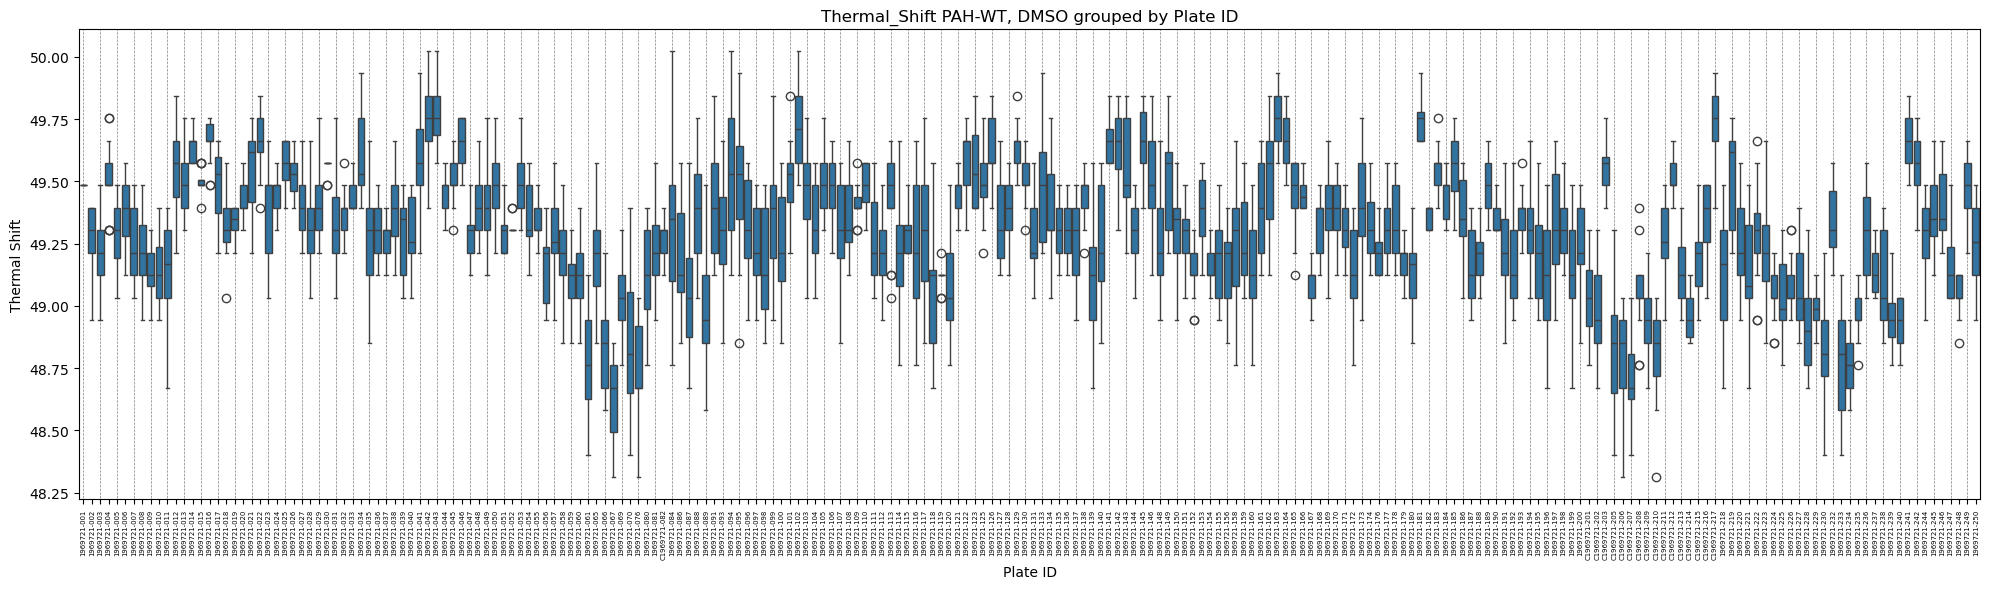

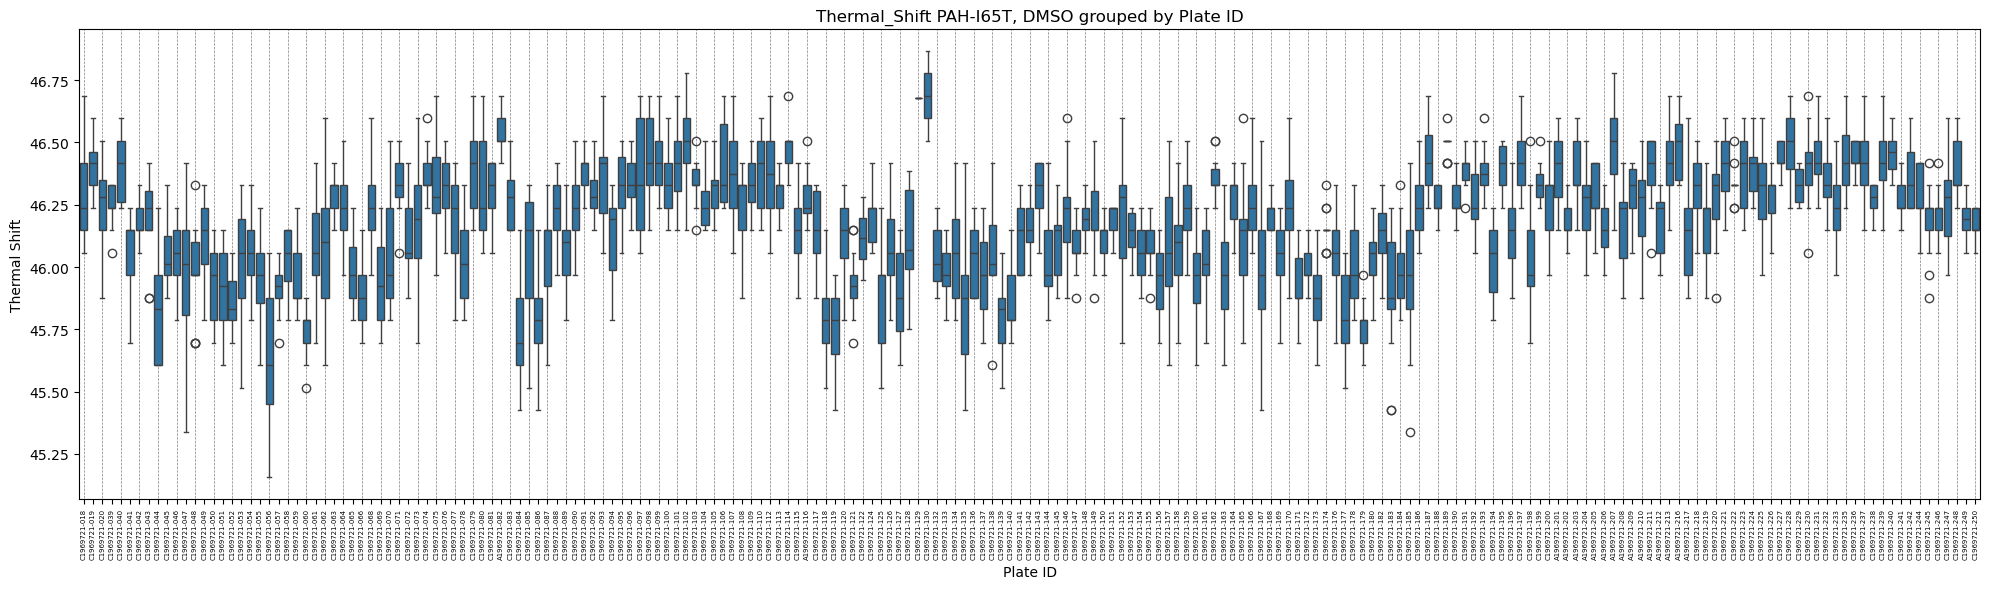

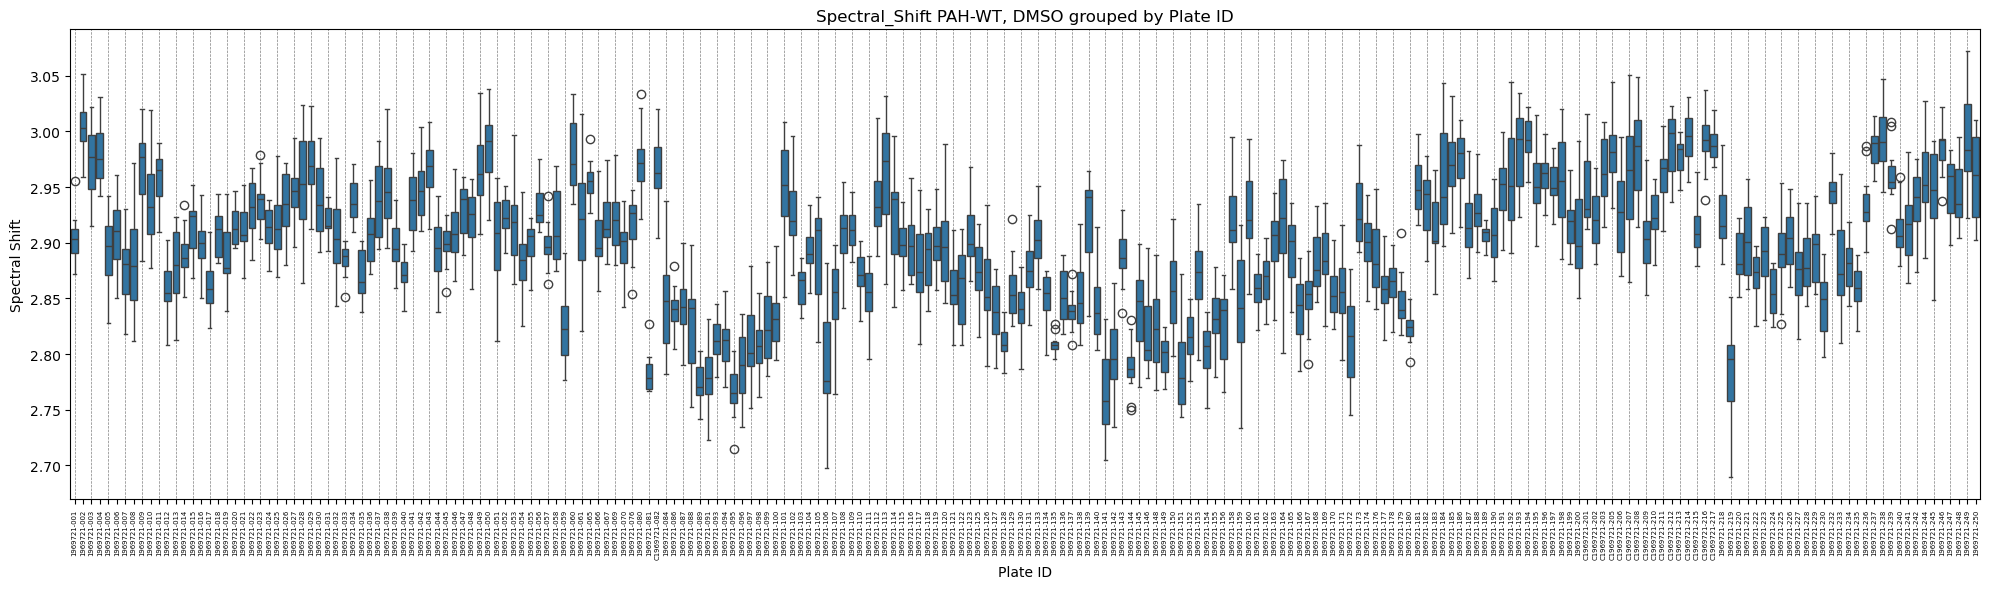

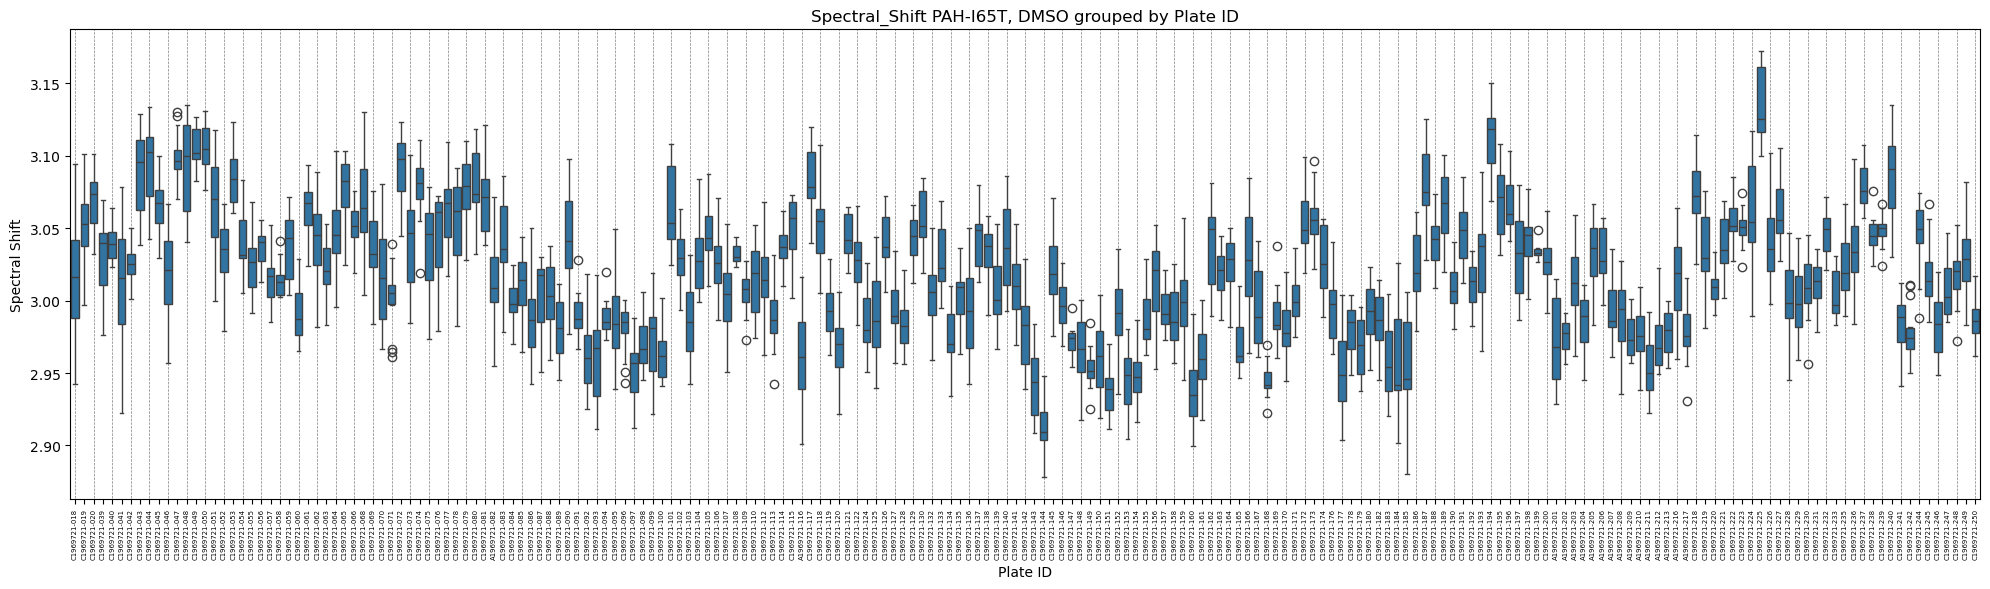

In [21]:
# Plot after outlier removal

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [22]:
iqr_other = df_other.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
iqr_crtl = df_ctrl.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
iqr_other = np.array(iqr_other)
iqr_crtl = np.array(iqr_crtl)

np.corrcoef(iqr_other, iqr_crtl)[0, 1], np.std(iqr_other)

(np.float64(0.2196128677580192), np.float64(0.06514107432657353))

In [23]:
iqr_other = df_other.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
iqr_crtl = df_ctrl.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
iqr_other = np.array(iqr_other)
iqr_crtl = np.array(iqr_crtl)

np.corrcoef(iqr_other, iqr_crtl)[0, 1], np.std(iqr_other)

(np.float64(0.36095673818546015), np.float64(0.010229178480338805))

In [24]:
# Normalise

df_other, df_ctrl = normalize_df(df_other,
                                 df_ctrl,
                                 assay = 'Thermal_Shift',
                                 method = 'median'
                                )
df_other, df_ctrl = normalize_df(df_other,
                                 df_ctrl,
                                 assay = 'Spectral_Shift',
                                 method = 'median'
                                )

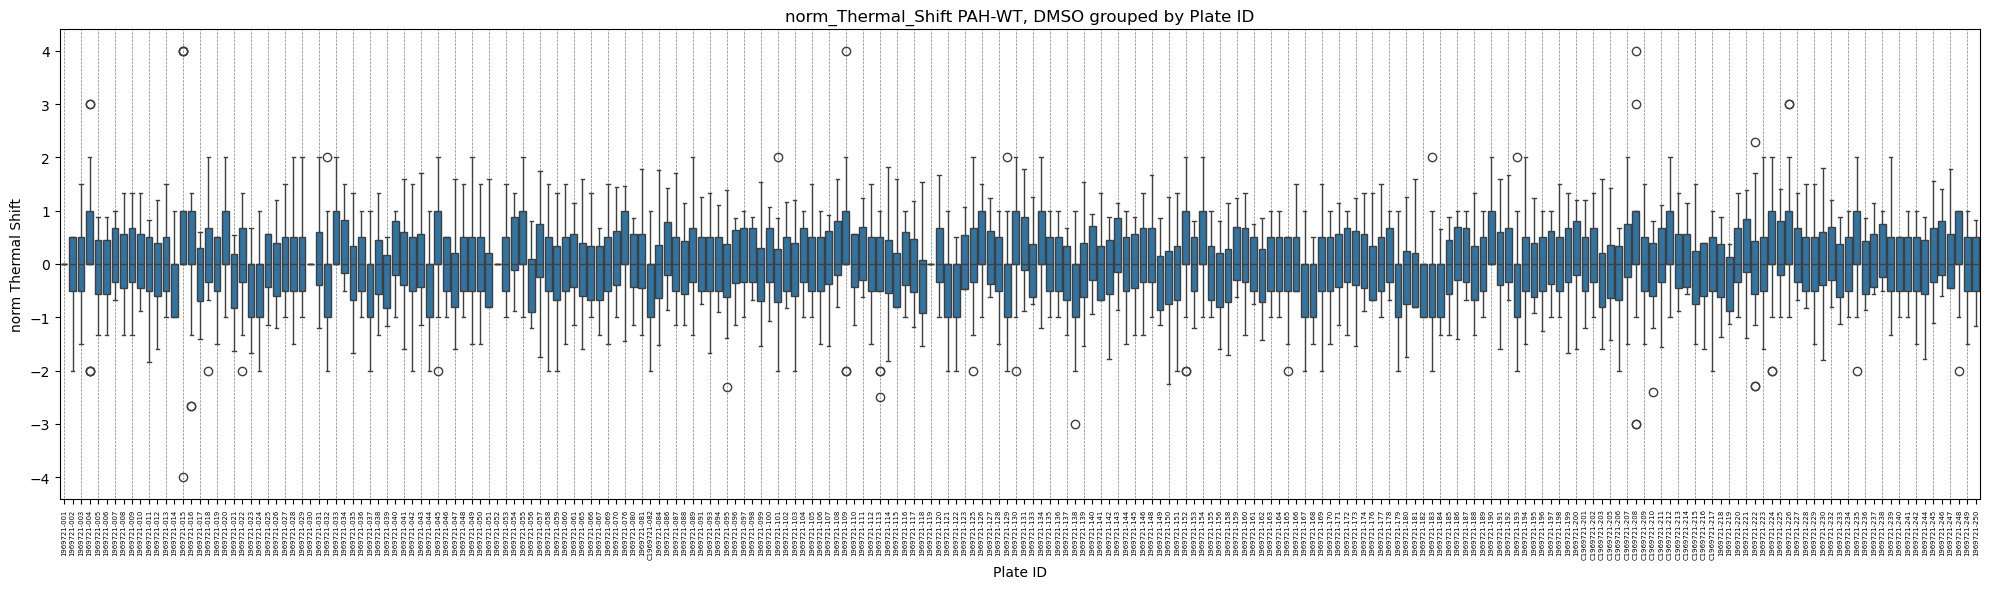

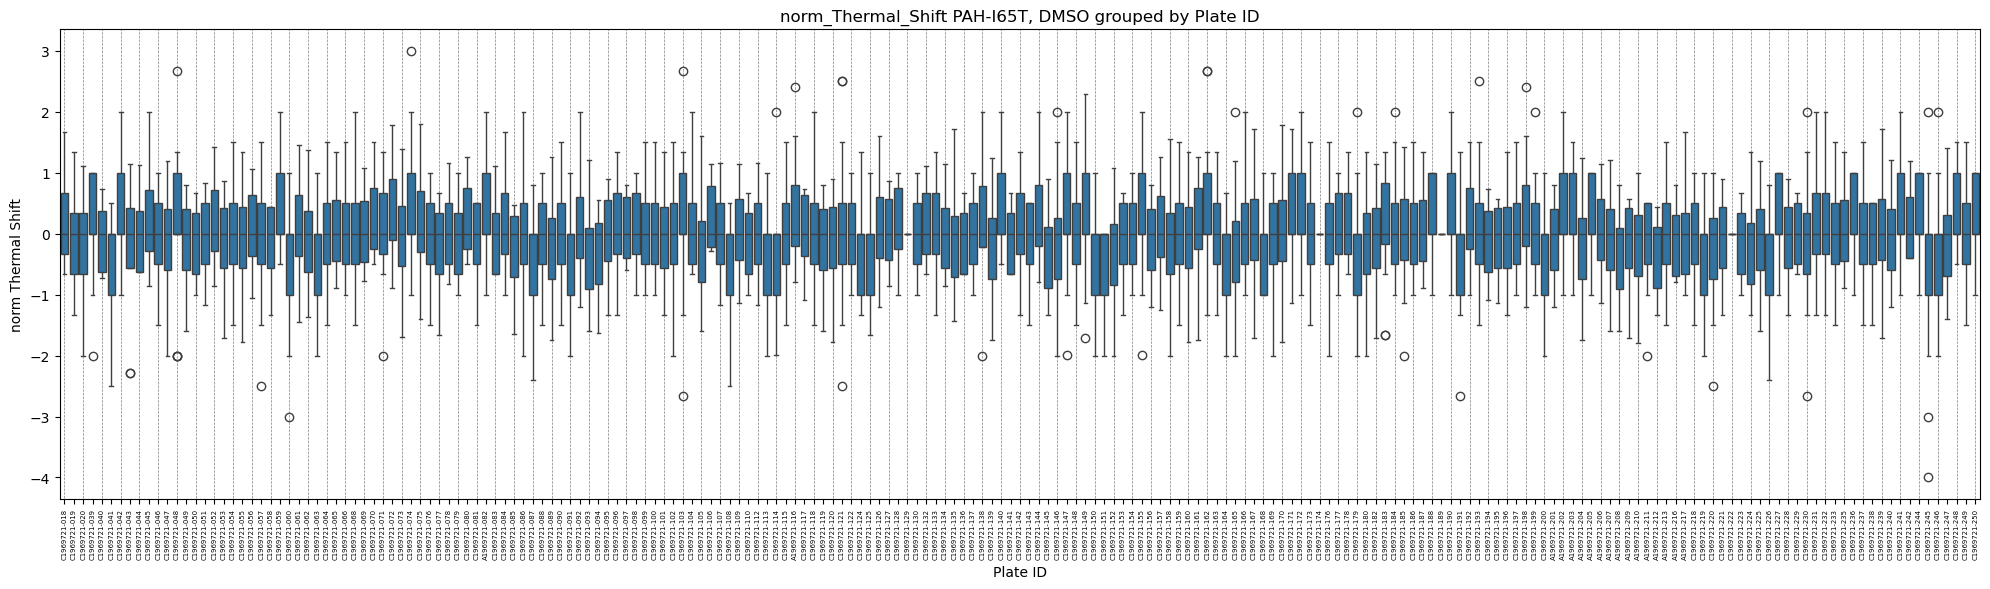

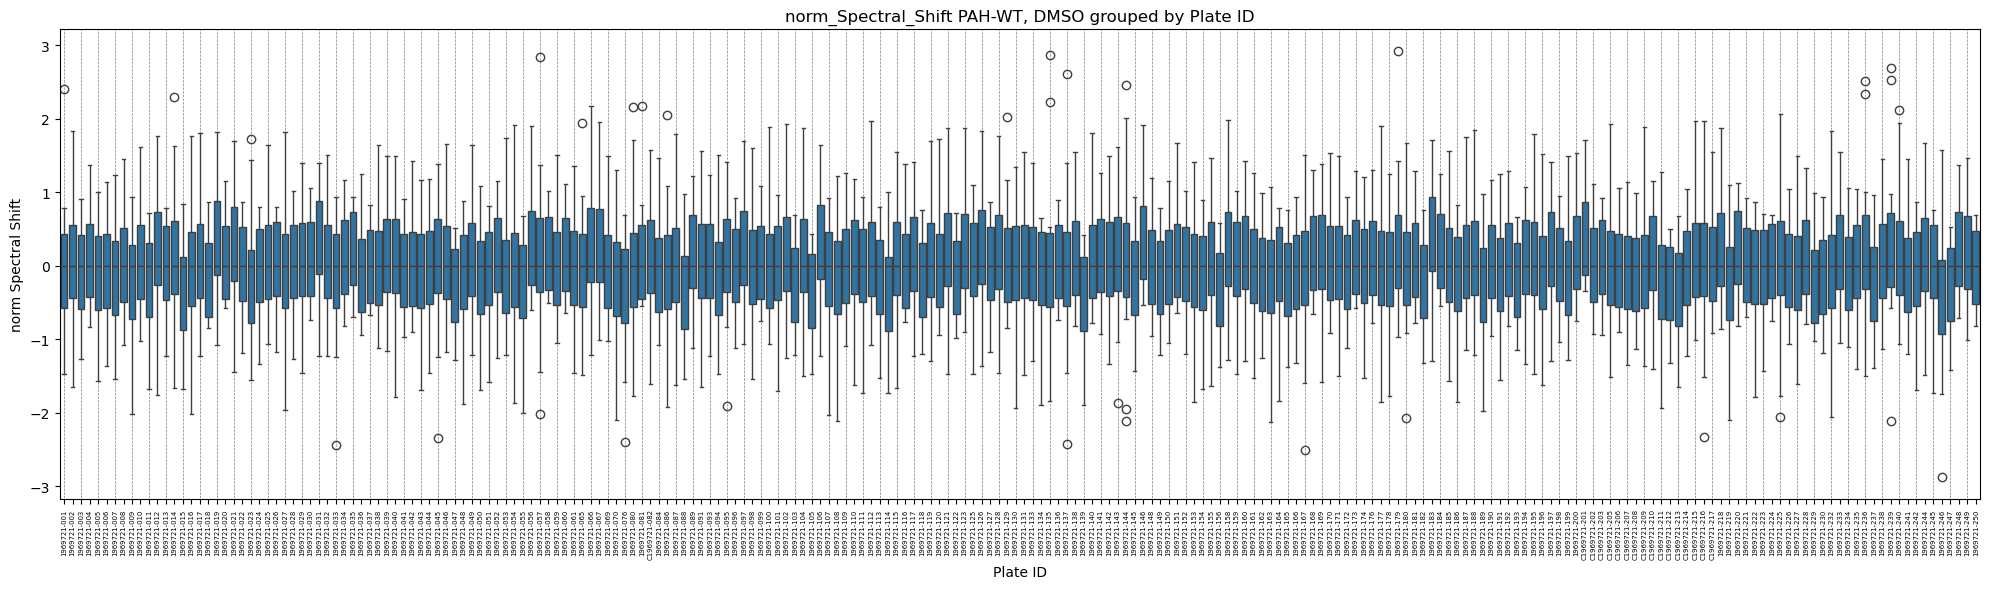

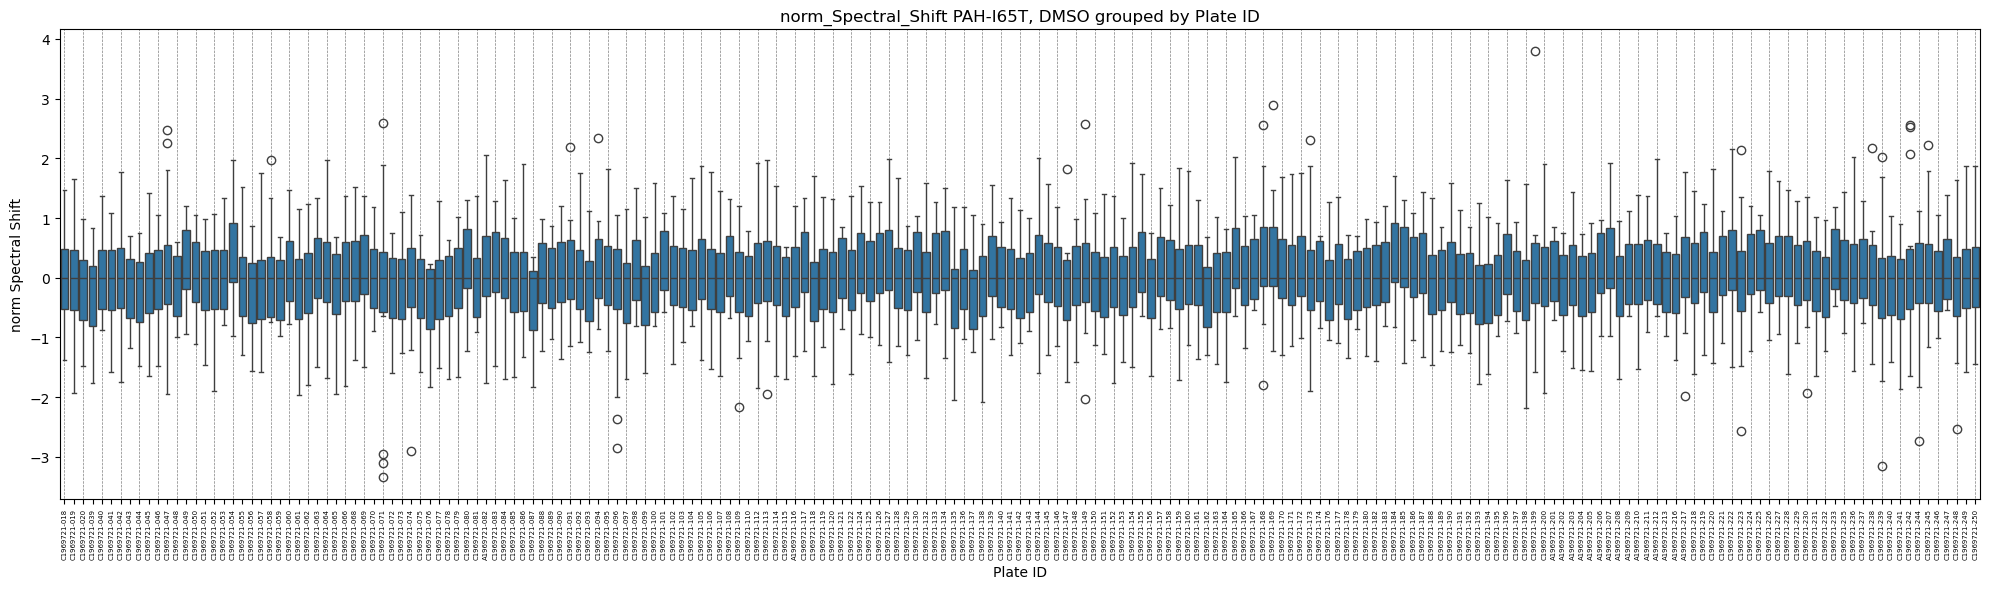

In [25]:
# Plot DMSO after normalization

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

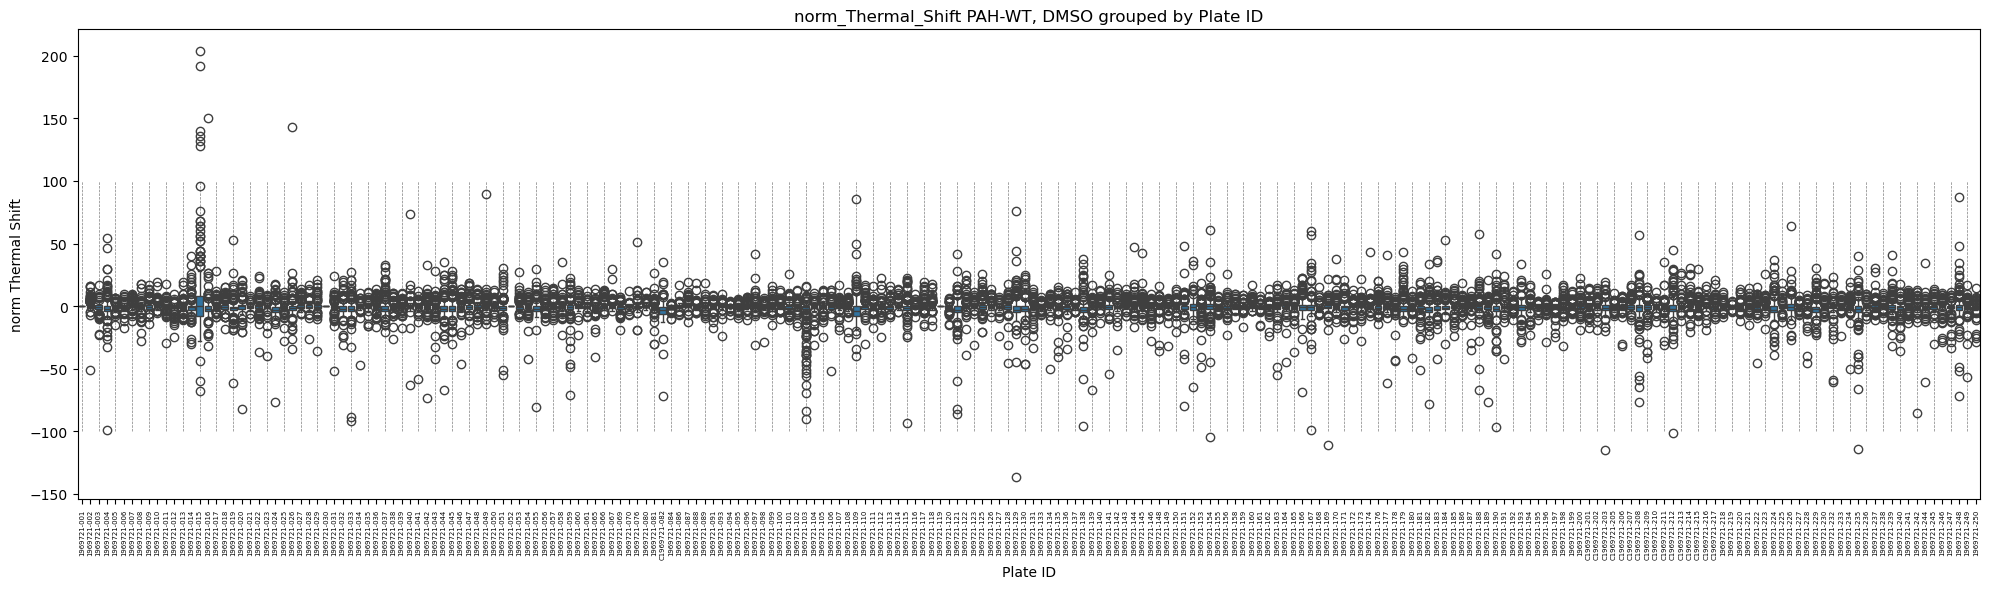

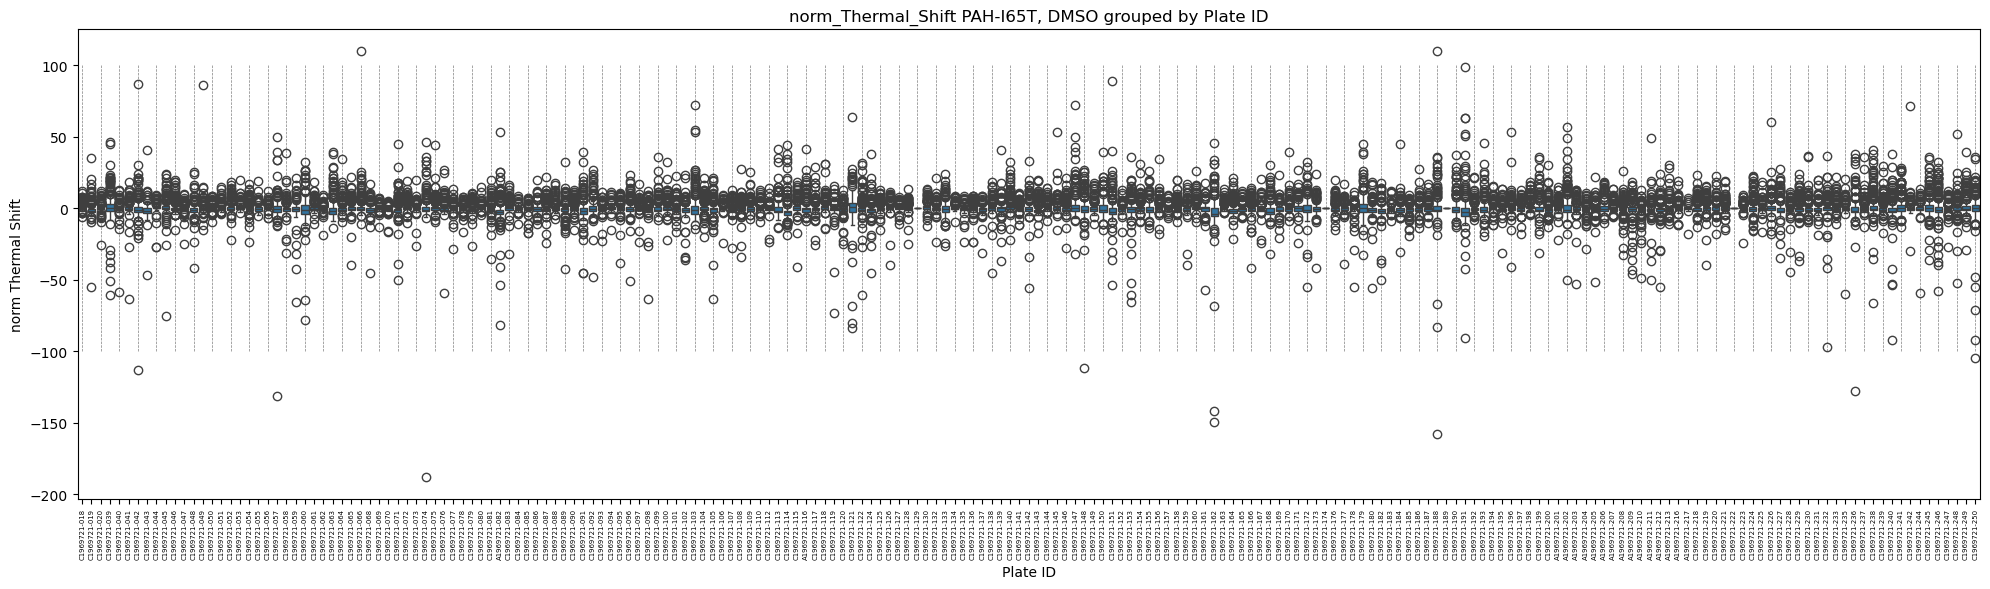

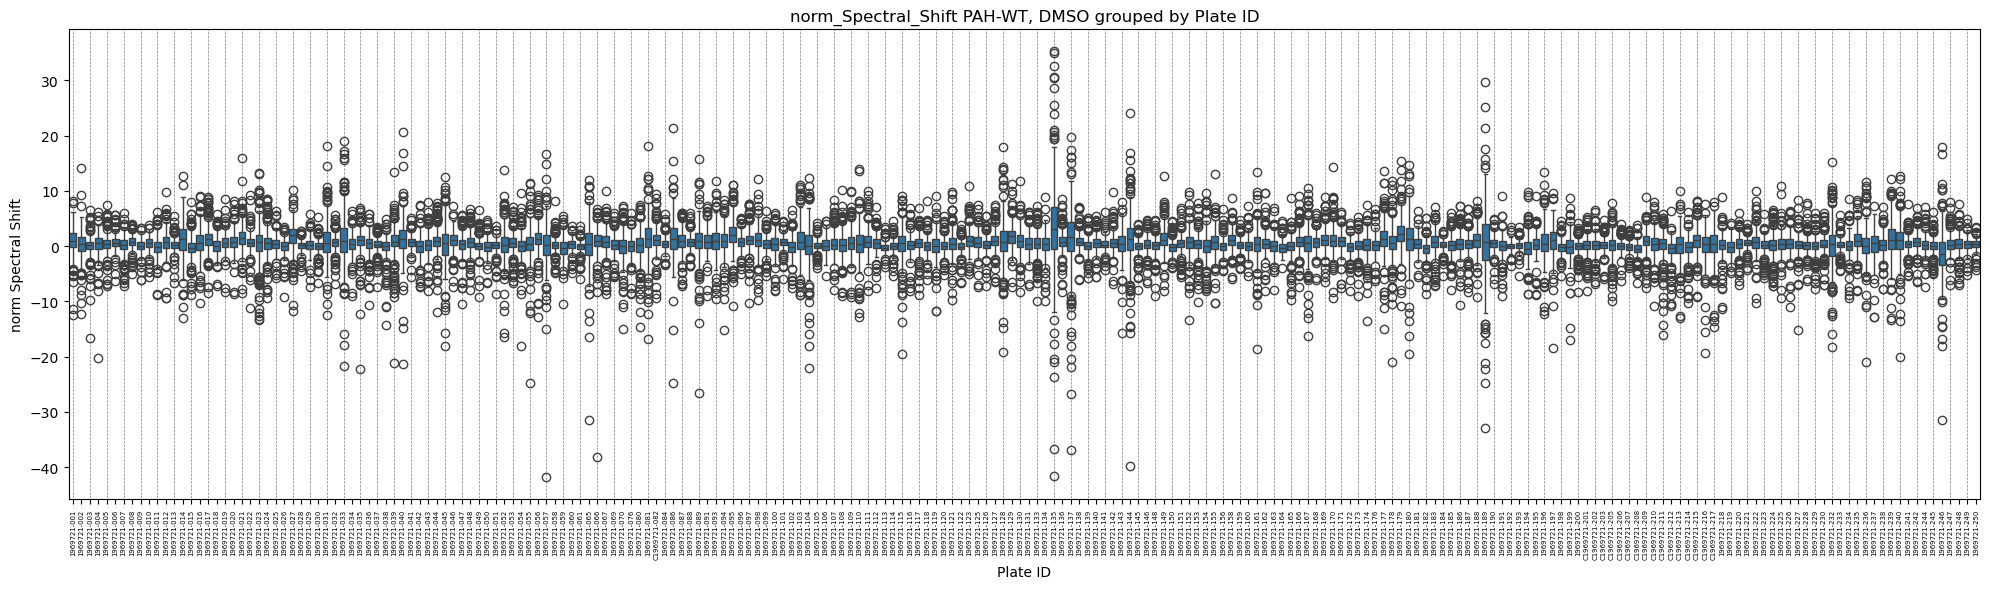

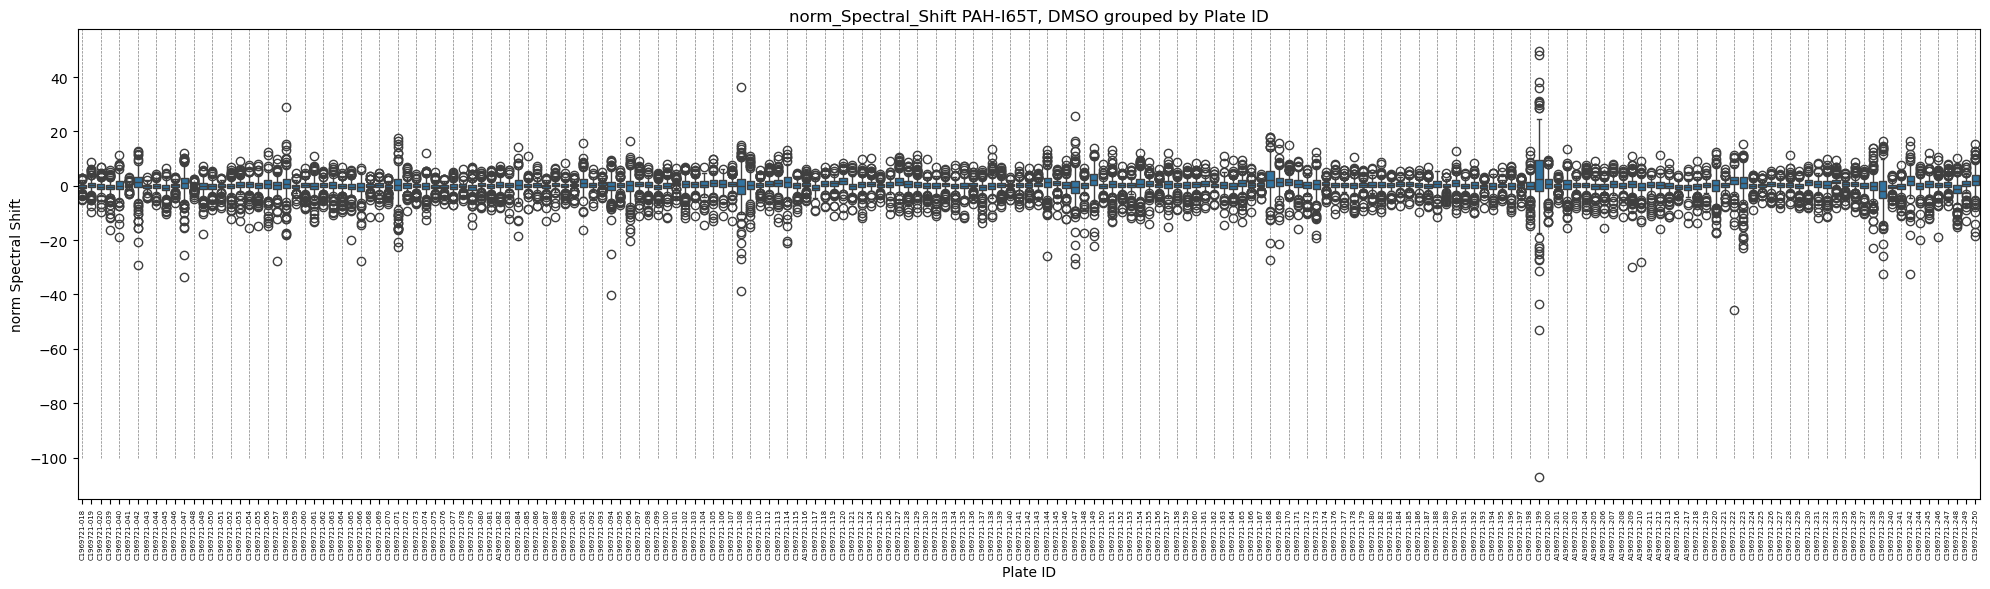

In [26]:
# Plot other after normalization

boxplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

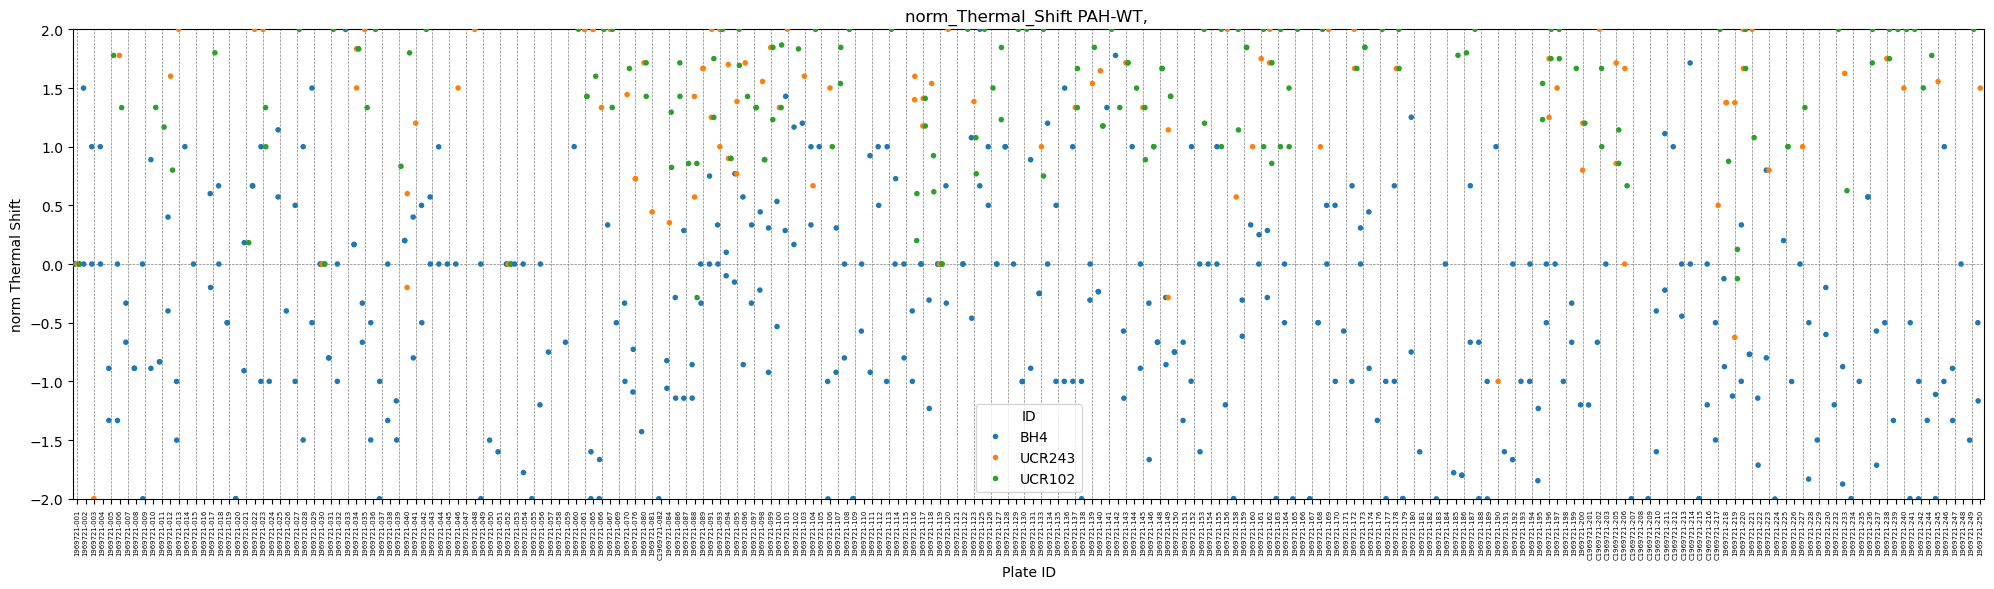

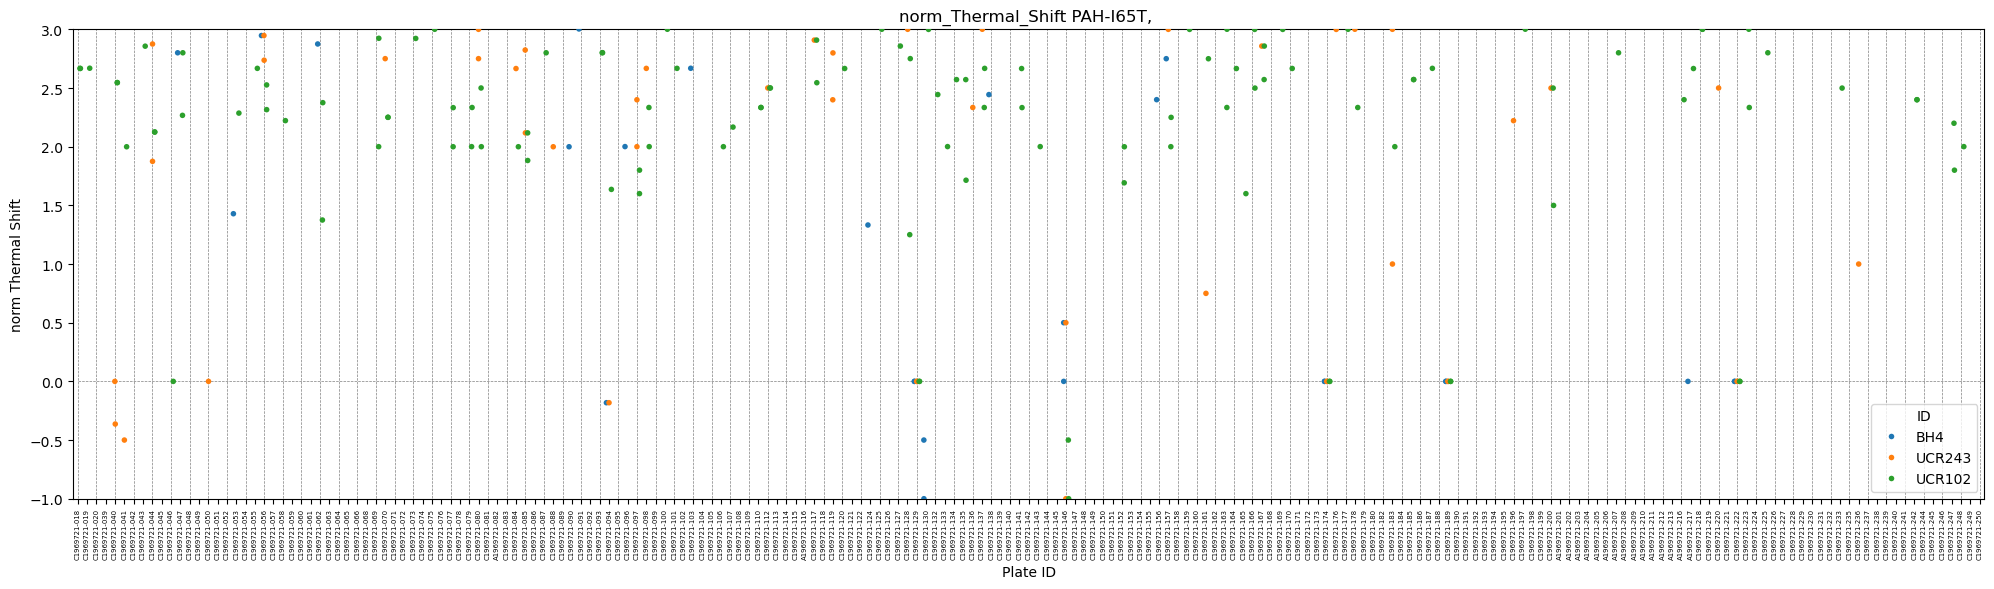

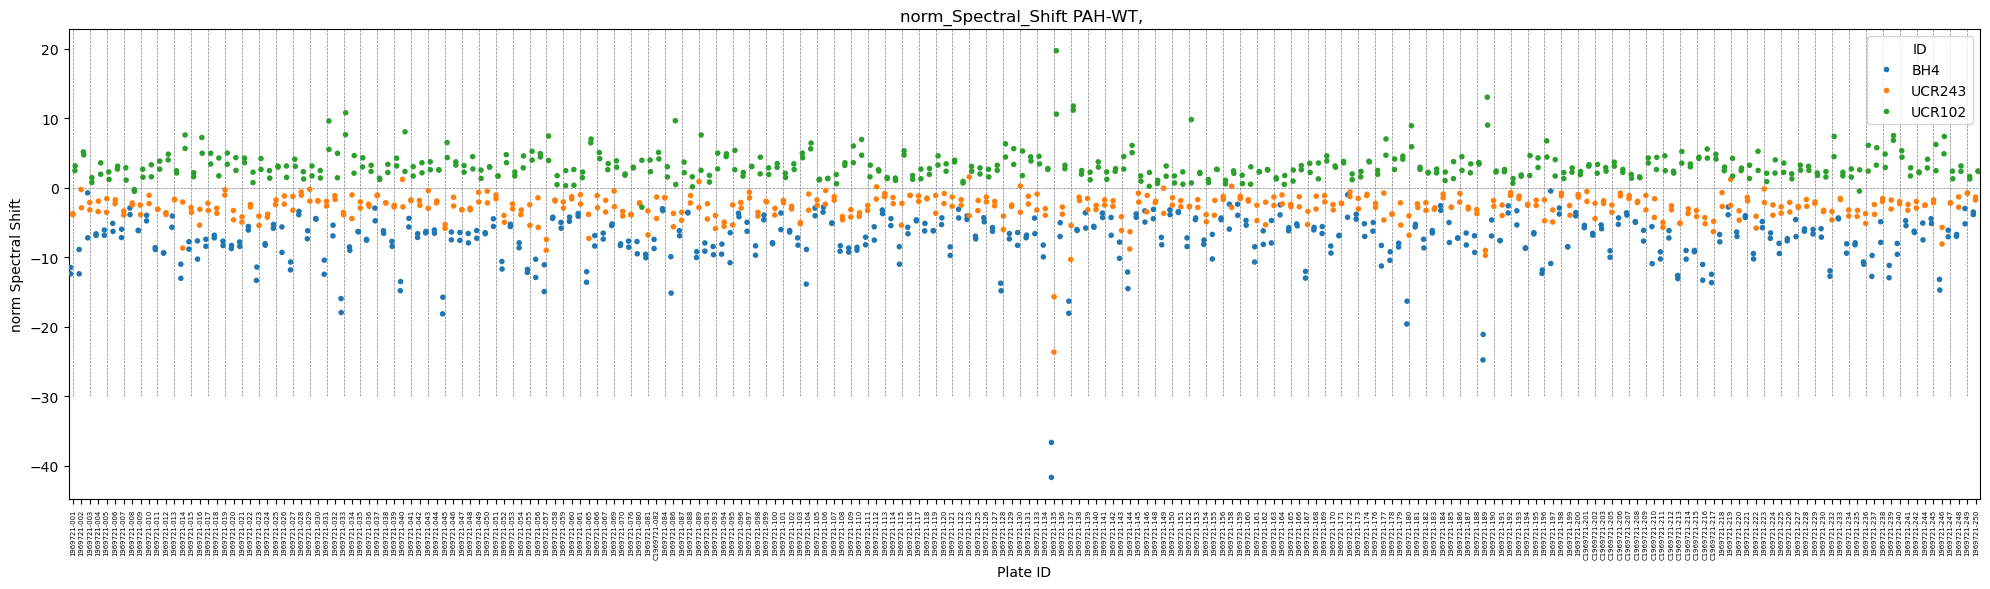

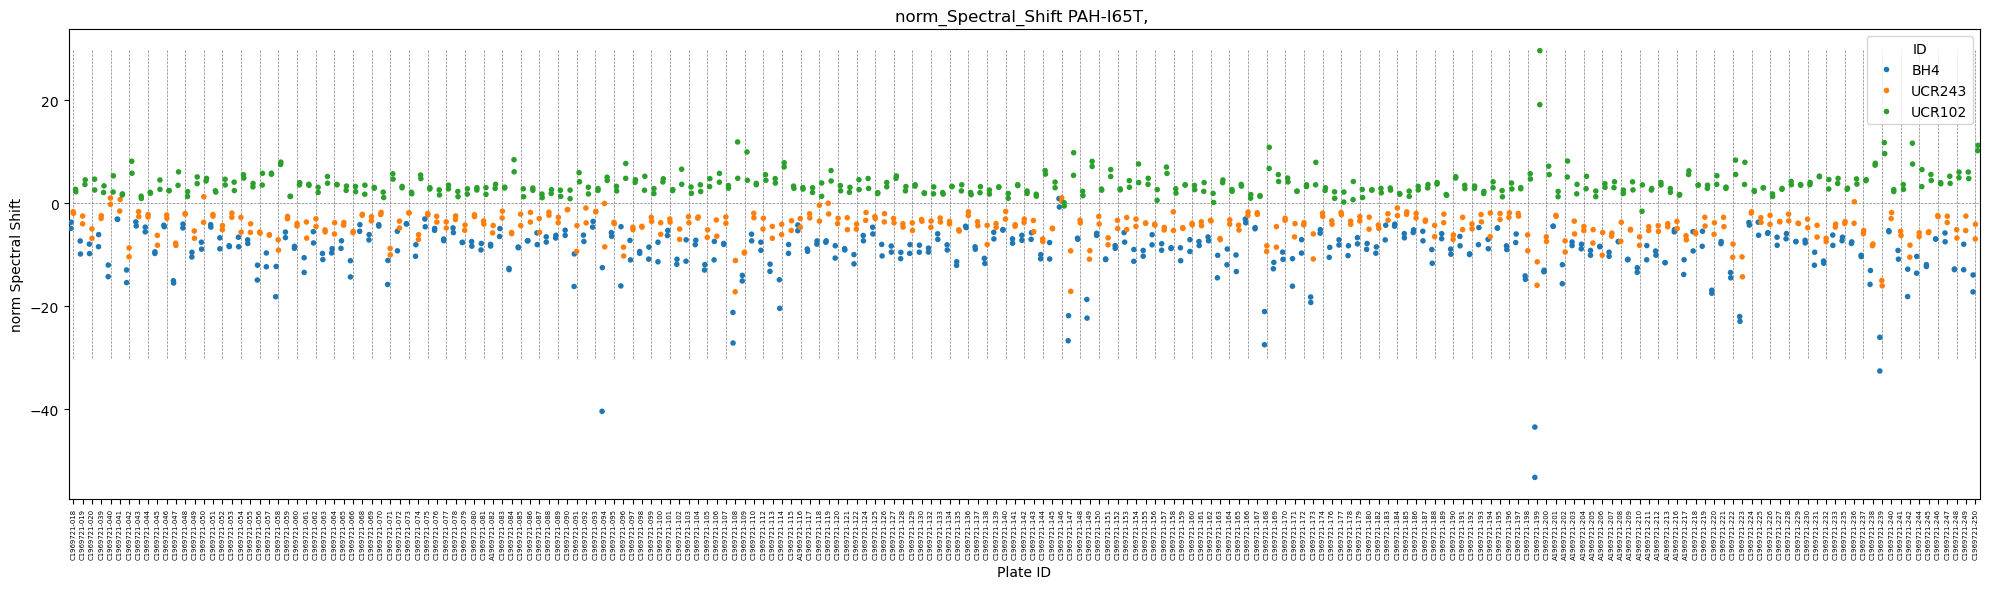

In [27]:
# Plot positive controls

dotplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-2, 2]
                 )

dotplot_per_plate(df_other, 
                  assay = 'norm_Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  ylim=[-1, 3]
                 )

dotplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-WT', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  #ylim=[-2, 2]
                 )

dotplot_per_plate(df_other, 
                  assay = 'norm_Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  ids = ['BH4', 'UCR243', 'UCR102'],
                  #ylim=[-2, 2]
                 )

In [28]:
# Complete the QC table by adding the distribuation of positive controls

df_qc_new = {}
for protein in ['PAH-WT', 'PAH-I65T']:
    df_qc_prot = df_qc.loc[df_qc['Protein'] == protein].copy()
    for pos_ctrl in ['BH4', 'UCR243', 'UCR102']:
        for assay in ['norm_Thermal_Shift', 'norm_Spectral_Shift']:
            df_qc_ = pos_ctrl_qc(df_other, protein, pos_ctrl, assay)
            df_qc_prot = pd.merge(df_qc_prot, df_qc_, left_index=True, right_index=True, how='outer')
    df_qc_new[protein] = df_qc_prot
df_qc_new = pd.concat(list(df_qc_new.values()))

df_qc_new

,Protein,TSA_median,TSA_iqr,SpSh_median,SpSh_iqr,out_of_distribution,abnormal_BH4_norm_Thermal_Shift,abnormal_BH4_norm_Spectral_Shift,abnormal_UCR243_norm_Thermal_Shift,abnormal_UCR243_norm_Spectral_Shift,abnormal_UCR102_norm_Thermal_Shift,abnormal_UCR102_norm_Spectral_Shift
1969721-001,PAH-WT,49.48400,0.000000,2.903465,0.031402,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-002,PAH-WT,49.34870,0.180400,3.001054,0.034008,no,0.0,0.0,0.0,0.0,0.0,0.0
1969721-003,PAH-WT,49.21340,0.180400,2.976828,0.049121,no,0.0,0.0,1.0,0.0,0.0,0.0
1969721-004,PAH-WT,49.48400,0.135200,2.972701,0.043583,no,0.0,0.0,1.0,0.0,1.0,0.0
1969721-005,PAH-WT,49.30360,0.202950,2.897231,0.044305,no,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
C1969721-246,PAH-I65T,46.23750,0.112750,2.986603,0.036365,no,0.0,0.0,1.0,0.0,0.0,0.0
C1969721-247,PAH-I65T,46.28260,0.225475,3.002388,0.031860,no,0.0,0.0,0.0,0.0,0.0,0.0
C1969721-248,PAH-I65T,46.37275,0.202850,3.010709,0.034555,no,0.0,0.0,0.0,0.0,0.0,0.0
C1969721-249,PAH-I65T,46.19240,0.090200,3.029309,0.023824,no,0.0,0.0,1.0,0.0,1.0,0.0


In [29]:
df_qc_new.loc['C1969721-205']

Protein                                  PAH-WT
TSA_median                              48.8527
TSA_iqr                                0.315675
SpSh_median                            2.981141
SpSh_iqr                               0.032759
out_of_distribution                          no
abnormal_BH4_norm_Thermal_Shift             2.0
abnormal_BH4_norm_Spectral_Shift            0.0
abnormal_UCR243_norm_Thermal_Shift          0.0
abnormal_UCR243_norm_Spectral_Shift         0.0
abnormal_UCR102_norm_Thermal_Shift          0.0
abnormal_UCR102_norm_Spectral_Shift         0.0
Name: C1969721-205, dtype: object

In [30]:
# Save
print(save_tag)
df_other.to_csv(f"data/PO_norm_analysed_{save_tag}_.csv")
df_ctrl.to_csv(f"data/PO_norm_analysed_dmso_{save_tag}_.csv")
df_qc_new.to_csv(f"data/qc_table_alpha_01_bonf_{save_tag}_.csv")

7jul
